# News Topic Classification with Deep Learning

This notebook reproduces the full benchmark for the repository. It compares TF-IDF and Skip-gram Word2Vec representations across 24 tuned configurations for four-class news headline classification.

Dataset files are expected at `data/Training_data_9.csv` and `data/Test_data.csv`. The rendered outputs document the completed experiment; rerunning the notebook requires the dataset and the dependencies in `requirements.txt`.


## 1. Install and Import Libraries

Run this cell first. The notebook uses PyTorch for neural networks and Gensim for Skip-gram Word2Vec.

In [1]:
import os
import re
import html
import json
import random
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

!pip install gensim
import gensim
from gensim.models import Word2Vec

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

try:
    import nltk
    from nltk.stem import PorterStemmer, WordNetLemmatizer
    nltk.download("wordnet", quiet=True)
    nltk.download("omw-1.4", quiet=True)
except Exception:
    nltk = None
    PorterStemmer = None
    WordNetLemmatizer = None

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Reproducibility Settings

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 3. Load Training and Testing CSV Files

The test set is kept separate and is not used during hyperparameter tuning.

In [3]:
TRAIN_PATH = "data/Training_data_9.csv"
TEST_PATH = "data/Test_data.csv"



train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

TEXT_COL = "News Headline"
LABEL_COL = "News Topic"

print("Training shape:", train_raw.shape)
print("Testing shape:", test_raw.shape)
display(train_raw.head())
display(test_raw.head())

Training shape: (88829, 2)
Testing shape: (12000, 2)


,News Headline,News Topic
0,<html> <body> News Headlines:\n <br> <b> Jacks...,Sports
1,<html> <body> News Headlines:\n <br> <b> Howar...,World News
2,<html> <body> News Headlines:\n <br> <b> WinXP...,Science and Technology
3,<html> <body> News Headlines:\n <br> <b> Chief...,Sports
4,<html> <body> News Headlines:\n <br> <b> Poll ...,World News


,News Headline,News Topic
0,<html> <body> <br> <br> News Headlines:\n <b>...,Science and Technology
1,<html> <body> <br> <br> News Headlines:\n <b>...,Science and Technology
2,<html> <body> <br> <br> News Headlines:\n <b>...,World News
3,<html> <body> <br> <br> News Headlines:\n <b>...,Business
4,<html> <body> <br> <br> News Headlines:\n <b>...,Business


## 4. Basic Dataset Inspection

In [4]:
print("Training columns:", train_raw.columns.tolist())
print("Testing columns:", test_raw.columns.tolist())
print("\nTraining data types:")
print(train_raw.dtypes)
print("\nTesting data types:")
print(test_raw.dtypes)
print("\nTraining missing values:")
print(train_raw.isna().sum())
print("\nTesting missing values:")
print(test_raw.isna().sum())
print("\nTraining duplicate rows:", train_raw.duplicated().sum())
print("Testing duplicate rows:", test_raw.duplicated().sum())
print("Training duplicate texts:", train_raw[TEXT_COL].duplicated().sum())
print("Testing duplicate texts:", test_raw[TEXT_COL].duplicated().sum())

Training columns: ['News Headline', 'News Topic']
Testing columns: ['News Headline', 'News Topic']

Training data types:
News Headline    object
News Topic       object
dtype: object

Testing data types:
News Headline    object
News Topic       object
dtype: object

Training missing values:
News Headline    0
News Topic       0
dtype: int64

Testing missing values:
News Headline    0
News Topic       0
dtype: int64

Training duplicate rows: 28833
Testing duplicate rows: 0
Training duplicate texts: 28833
Testing duplicate texts: 0


## 5. Duplicate Handling Decision

Exact duplicates in the training set can cause validation leakage if identical headlines appear in both the training and validation split. Therefore, duplicates are removed from the training set only. The test set is not modified except for standard text transformation during evaluation.

In [5]:
train_df = train_raw.drop_duplicates().reset_index(drop=True)
test_df = test_raw.copy().reset_index(drop=True)

train_test_overlap = len(set(train_df[TEXT_COL]).intersection(set(test_df[TEXT_COL])))

print("Training shape after duplicate removal:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Exact text overlap between train and test:", train_test_overlap)

Training shape after duplicate removal: (59996, 2)
Testing shape: (12000, 2)
Exact text overlap between train and test: 0


## 6. Class Distribution EDA

,class,count,percentage
0,Sports,19831,33.05
1,World News,18617,31.03
2,Business,11801,19.67
3,Science and Technology,9747,16.25


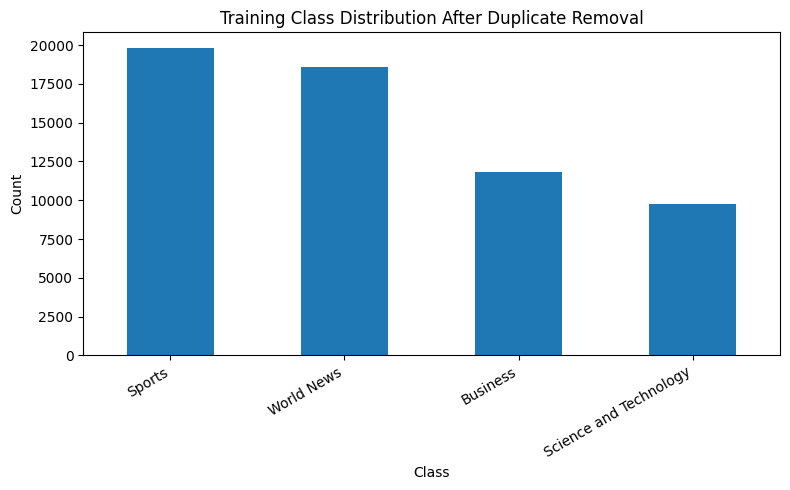

,class,count,percentage
0,Science and Technology,3000,25.0
1,World News,3000,25.0
2,Business,3000,25.0
3,Sports,3000,25.0


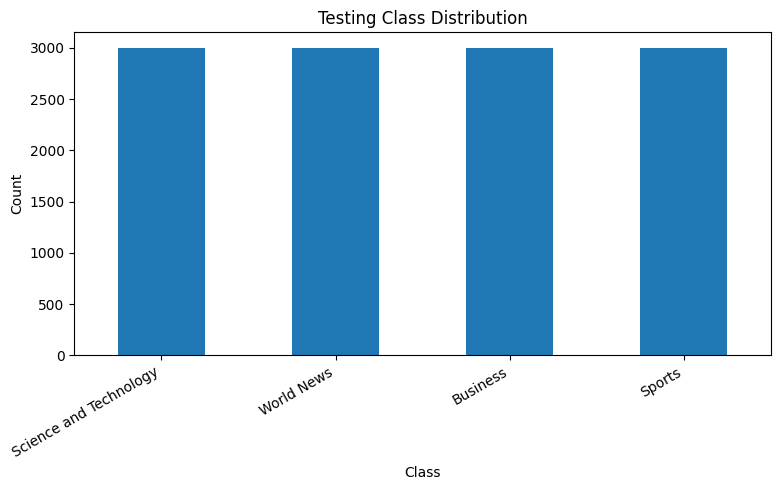

In [6]:
def plot_class_distribution(df, title):
    counts = df[LABEL_COL].value_counts()
    display(pd.DataFrame({"class": counts.index, "count": counts.values, "percentage": (counts.values / len(df) * 100).round(2)}))
    ax = counts.plot(kind="bar")
    ax.set_title(title)
    ax.set_xlabel("Class")
    ax.set_ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

plot_class_distribution(train_df, "Training Class Distribution After Duplicate Removal")
plot_class_distribution(test_df, "Testing Class Distribution")

## 7. Text Cleaning Helper for EDA

This helper removes HTML tags only for EDA readability.

In [7]:
def strip_html_for_eda(text):
    text = html.unescape(str(text))
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = re.sub(r"News Headlines:", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["eda_text"] = train_df[TEXT_COL].apply(strip_html_for_eda)
test_df["eda_text"] = test_df[TEXT_COL].apply(strip_html_for_eda)

display(train_df[[TEXT_COL, "eda_text", LABEL_COL]].head())

,News Headline,eda_text,News Topic
0,<html> <body> News Headlines:\n <br> <b> Jacks...,"Jackson second to Leslie for MVP UNCASVILLE, C...",Sports
1,<html> <body> News Headlines:\n <br> <b> Howar...,Howard plans regional spy school Australian le...,World News
2,<html> <body> News Headlines:\n <br> <b> WinXP...,WinXP SP2 Home Edition To Be Available On Auto...,Science and Technology
3,<html> <body> News Headlines:\n <br> <b> Chief...,Chiefs #39; 1st win of season stuns Ravens #39...,Sports
4,<html> <body> News Headlines:\n <br> <b> Poll ...,Poll blow for Hong Kong democrats Hong Kong's ...,World News


## 8. Text Length Analysis

,split,min_words,mean_words,median_words,max_words,min_chars,mean_chars,median_chars,max_chars
0,train,9,37.94,37.0,170,47,232.47,230.0,974
1,test,7,37.73,37.0,177,34,232.36,230.0,967


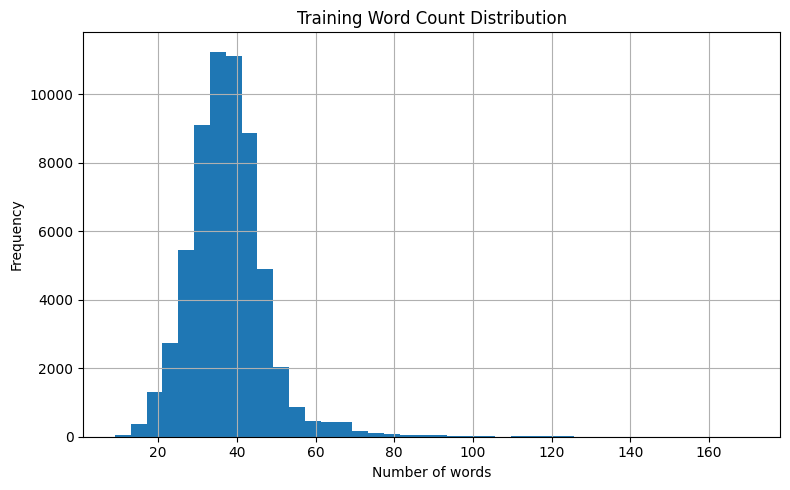

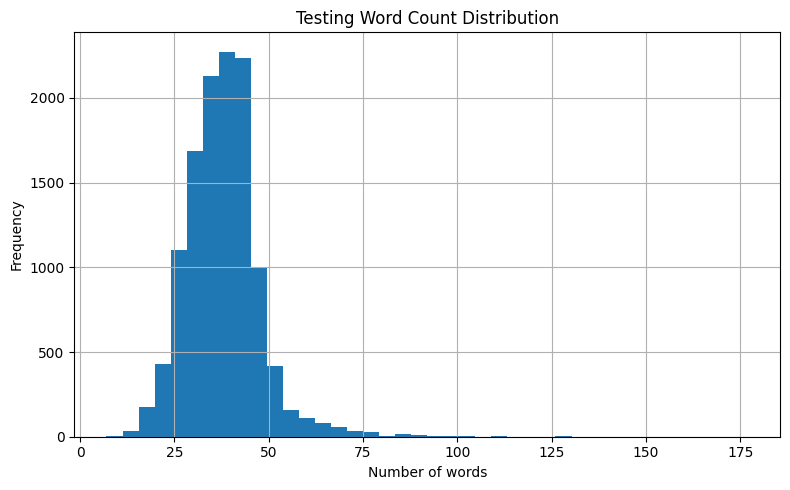

In [8]:
for df in [train_df, test_df]:
    df["word_count"] = df["eda_text"].apply(lambda x: len(x.split()))
    df["char_count"] = df["eda_text"].apply(len)

length_summary = pd.DataFrame({
    "split": ["train", "test"],
    "min_words": [train_df["word_count"].min(), test_df["word_count"].min()],
    "mean_words": [train_df["word_count"].mean(), test_df["word_count"].mean()],
    "median_words": [train_df["word_count"].median(), test_df["word_count"].median()],
    "max_words": [train_df["word_count"].max(), test_df["word_count"].max()],
    "min_chars": [train_df["char_count"].min(), test_df["char_count"].min()],
    "mean_chars": [train_df["char_count"].mean(), test_df["char_count"].mean()],
    "median_chars": [train_df["char_count"].median(), test_df["char_count"].median()],
    "max_chars": [train_df["char_count"].max(), test_df["char_count"].max()],
})

display(length_summary.round(2))

for split_name, df in [("Training", train_df), ("Testing", test_df)]:
    ax = df["word_count"].hist(bins=40)
    ax.set_title(f"{split_name} Word Count Distribution")
    ax.set_xlabel("Number of words")
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 9. Frequent Words by Class

In [9]:
def basic_tokens(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    return [token for token in text.split() if token not in ENGLISH_STOP_WORDS and len(token) > 2]

def top_words_for_class(df, class_name, top_n=20):
    all_tokens = []
    for text in df.loc[df[LABEL_COL] == class_name, "eda_text"]:
        all_tokens.extend(basic_tokens(text))
    return pd.DataFrame(Counter(all_tokens).most_common(top_n), columns=["word", "count"])

for class_name in sorted(train_df[LABEL_COL].unique()):
    print("\nClass:", class_name)
    display(top_words_for_class(train_df, class_name, 20))


Class: Business


,word,count
0,said,2925
1,reuters,2690
2,new,2641
3,oil,2540
4,prices,1730
5,company,1591
6,percent,1354
7,york,1349
8,year,1294
9,corp,1194



Class: Science and Technology


,word,count
0,new,2339
1,microsoft,1584
2,said,1177
3,software,1176
4,internet,1081
5,reuters,1042
6,space,904
7,quot,860
8,company,859
9,search,760



Class: Sports


,word,count
0,game,2875
1,new,2778
2,season,2359
3,win,2328
4,team,2245
5,night,2033
6,world,1972
7,cup,1800
8,league,1799
9,victory,1775



Class: World News


,word,count
0,said,4841
1,iraq,3409
2,reuters,3302
3,president,2603
4,new,2229
5,afp,2137
6,minister,2105
7,killed,1930
8,people,1795
9,government,1607


## 10. Word Clouds by Class

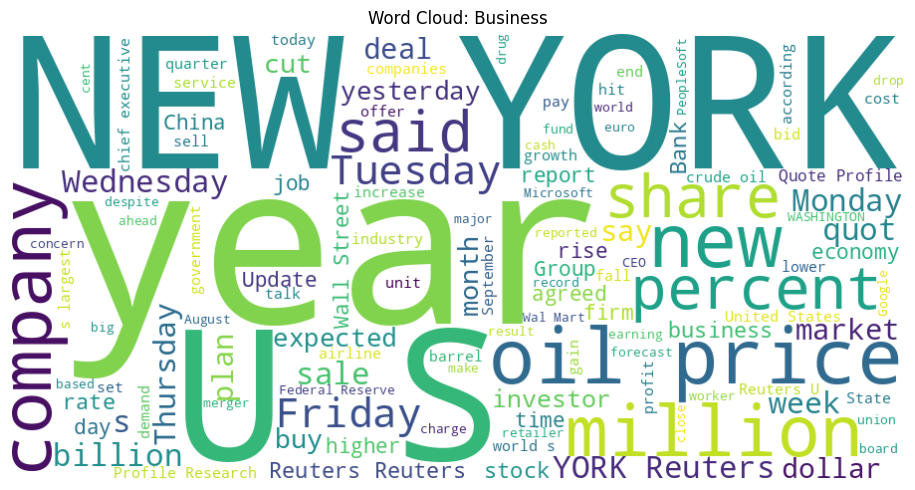

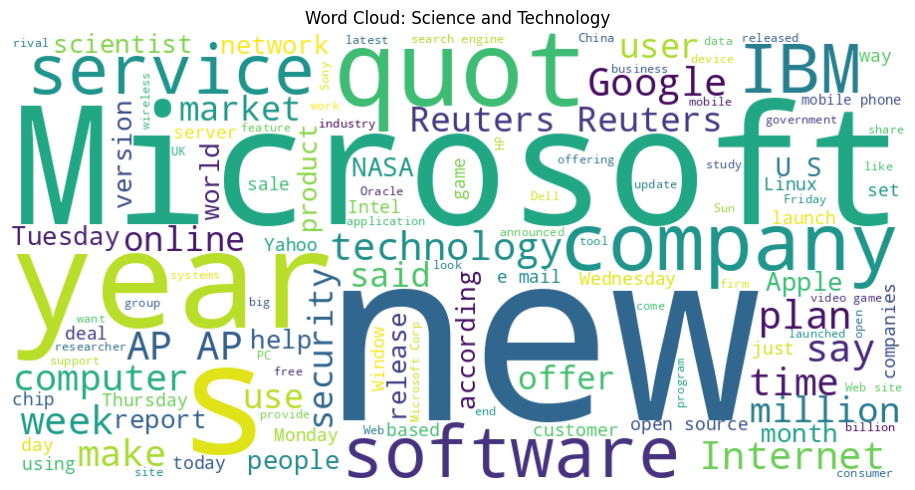

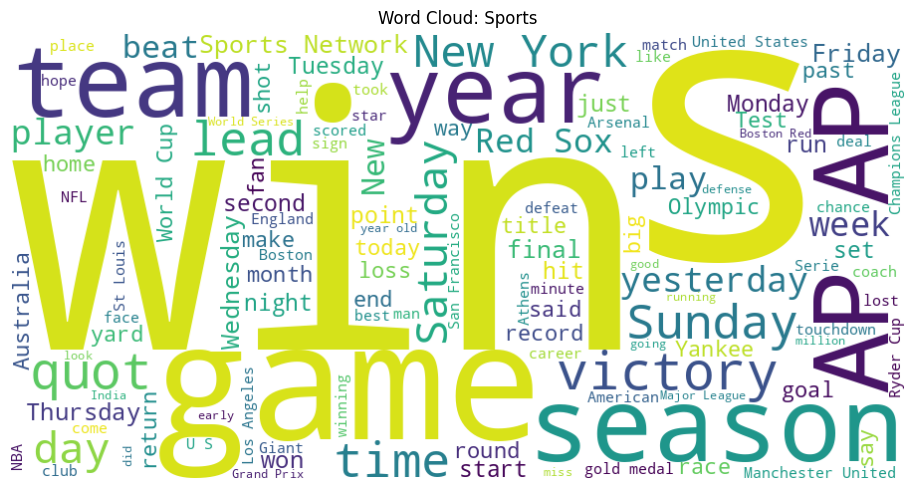

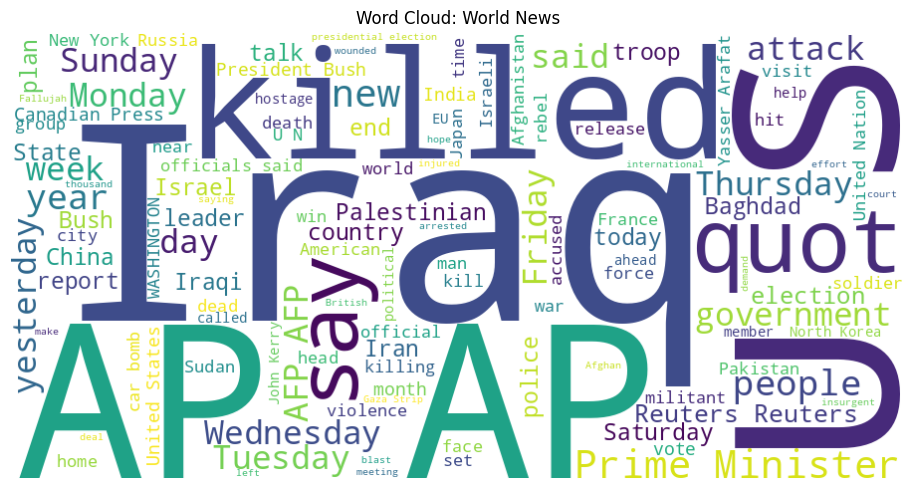

In [10]:
for class_name in sorted(train_df[LABEL_COL].unique()):
    class_text = " ".join(train_df.loc[train_df[LABEL_COL] == class_name, "eda_text"].tolist())
    wc = WordCloud(width=900, height=450, background_color="white", stopwords=set(ENGLISH_STOP_WORDS), max_words=120).generate(class_text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud: {class_name}")
    plt.tight_layout()
    plt.show()

## 12. Train/Validation Split

Only the training CSV is split into training and validation. The testing CSV is kept untouched for final evaluation.

In [11]:
train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df[LABEL_COL]
)

label_encoder = LabelEncoder()
label_encoder.fit(train_df[LABEL_COL])

class_names = label_encoder.classes_.tolist()
num_classes = len(class_names)

train_labels = label_encoder.transform(train_part[LABEL_COL])
val_labels = label_encoder.transform(val_part[LABEL_COL])
test_labels = label_encoder.transform(test_df[LABEL_COL])

print("Train split:", train_part.shape)
print("Validation split:", val_part.shape)
print("Test split:", test_df.shape)
print("Classes:", class_names)

Train split: (47996, 5)
Validation split: (12000, 5)
Test split: (12000, 5)
Classes: ['Business', 'Science and Technology', 'Sports', 'World News']


## 13. Three Preprocessing Versions

No preprocessing keeps the text as originally provided. Extreme preprocessing removes HTML, lowercases, removes punctuation/numbers/stopwords, and applies stemming and lemmatization. Optimum preprocessing is selected based on EDA: it removes HTML artifacts and wrapper text, lowercases, keeps useful numbers and apostrophes, and normalizes whitespace.

In [12]:
stemmer = PorterStemmer() if PorterStemmer is not None else None
lemmatizer = WordNetLemmatizer() if WordNetLemmatizer is not None else None
stop_words = set(ENGLISH_STOP_WORDS)

def remove_html_and_wrapper(text):
    text = html.unescape(str(text))
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = re.sub(r"News Headlines:", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def no_preprocess(text):
    return str(text)

def safe_lemmatize(token):
    if lemmatizer is None:
        return token
    try:
        return lemmatizer.lemmatize(token)
    except Exception:
        return token

def extreme_preprocess(text):
    text = remove_html_and_wrapper(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = []
    for token in text.split():
        if token in stop_words or len(token) <= 2:
            continue
        token = safe_lemmatize(token)
        if stemmer is not None:
            token = stemmer.stem(token)
        tokens.append(token)
    return " ".join(tokens)

def optimum_preprocess(text):
    text = remove_html_and_wrapper(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s'-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

preprocessors = {
    "no_preprocessing": no_preprocess,
    "extreme_preprocessing": extreme_preprocess,
    "optimum_preprocessing": optimum_preprocess,
}

for name, func in preprocessors.items():
    print("\n", name)
    print(func(train_part[TEXT_COL].iloc[0])[:500])


 no_preprocessing
<html> <body> News Headlines:
 <br> <b> NASA-SGI Supercomputer Tops in Speed and Research  quot;It #39;s one hell of a system, quot; said Columbia project manager Bill Thigpen, who told TechNewsWorld the system is being submitted for a top spot on the upcoming Top500 Supercomputer list due next month. </b> 
 <br> <br> 

 extreme_preprocessing
nasa sgi supercomput top speed research quot hell quot said columbia project manag thigpen told technewsworld submit spot upcom supercomput list month

 optimum_preprocessing
nasa-sgi supercomputer tops in speed and research quot it 39 s one hell of a system quot said columbia project manager bill thigpen who told technewsworld the system is being submitted for a top spot on the upcoming top500 supercomputer list due next month


## 14. Create Preprocessed Text Datasets

In [13]:
processed_data = {}

for prep_name, prep_func in preprocessors.items():
    print("Processing:", prep_name)
    processed_data[prep_name] = {
        "train_texts": train_part[TEXT_COL].apply(prep_func).tolist(),
        "val_texts": val_part[TEXT_COL].apply(prep_func).tolist(),
        "test_texts": test_df[TEXT_COL].apply(prep_func).tolist(),
    }
    print("Example:", processed_data[prep_name]["train_texts"][0][:250])

Processing: no_preprocessing
Example: <html> <body> News Headlines:
 <br> <b> NASA-SGI Supercomputer Tops in Speed and Research  quot;It #39;s one hell of a system, quot; said Columbia project manager Bill Thigpen, who told TechNewsWorld the system is being submitted for a top spot on th
Processing: extreme_preprocessing
Example: nasa sgi supercomput top speed research quot hell quot said columbia project manag thigpen told technewsworld submit spot upcom supercomput list month
Processing: optimum_preprocessing
Example: nasa-sgi supercomputer tops in speed and research quot it 39 s one hell of a system quot said columbia project manager bill thigpen who told technewsworld the system is being submitted for a top spot on the upcoming top500 supercomputer list due next


## 15. Evaluation Utilities

In [14]:
all_results = []
all_reports = {}
all_confusion_matrices = {}
all_predictions = {}


def evaluate_predictions(y_true, y_pred, title):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    matrix = confusion_matrix(y_true, y_pred)
    print(title)
    print("Accuracy:", round(acc, 4))
    print("Macro F1:", round(f1, 4))
    print(classification_report(y_true, y_pred, target_names=class_names))
    return acc, f1, report, matrix


def plot_confusion(matrix, title):
    disp = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=class_names)
    disp.plot(values_format="d", xticks_rotation=30)
    plt.title(title)
    plt.tight_layout()
    plt.show()


def log_result(preprocessing, representation, model_name, params, val_acc, val_f1, test_acc, test_f1, test_report, test_matrix, test_pred):
    key = f"{preprocessing} | {representation} | {model_name}"
    all_results.append({
        "preprocessing": preprocessing,
        "representation": representation,
        "model": model_name,
        "hyperparameters": json.dumps(params),
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "test_accuracy": test_acc,
        "test_macro_f1": test_f1,
    })
    all_reports[key] = test_report
    all_confusion_matrices[key] = test_matrix
    all_predictions[key] = test_pred

## 16. TF-IDF + Multinomial Naive Bayes with Manual Hyperparameter Tuning


TF-IDF + MultinomialNB: no_preprocessing


,alpha,max_features,ngram_range,val_accuracy,val_macro_f1
2,0.2,30000,"(1, 1)",0.912250,0.899205
3,0.2,30000,"(1, 2)",0.910667,0.897486
0,0.2,15000,"(1, 1)",0.910167,0.896873
7,0.5,30000,"(1, 2)",0.910000,0.896660
4,0.5,15000,"(1, 1)",0.909250,0.895921
6,0.5,30000,"(1, 1)",0.909167,0.895423
11,1.0,30000,"(1, 2)",0.907500,0.893746
1,0.2,15000,"(1, 2)",0.906667,0.892920
8,1.0,15000,"(1, 1)",0.906917,0.892804
5,0.5,15000,"(1, 2)",0.906250,0.892223


Best validation configuration: {'alpha': 0.2, 'max_features': 30000, 'ngram_range': (1, 1)}
Final Test: TF-IDF + MultinomialNB + no_preprocessing
Accuracy: 0.9007
Macro F1: 0.9001
                        precision    recall  f1-score   support

              Business       0.88      0.85      0.87      3000
Science and Technology       0.90      0.85      0.88      3000
                Sports       0.94      0.98      0.96      3000
            World News       0.88      0.91      0.90      3000

              accuracy                           0.90     12000
             macro avg       0.90      0.90      0.90     12000
          weighted avg       0.90      0.90      0.90     12000



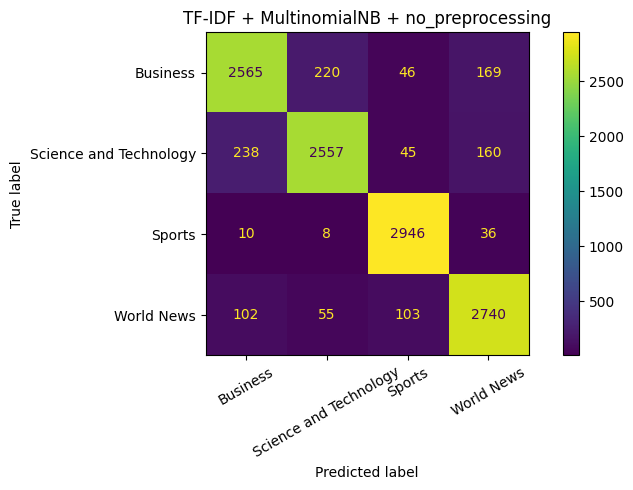


TF-IDF + MultinomialNB: extreme_preprocessing


,alpha,max_features,ngram_range,val_accuracy,val_macro_f1
3,0.2,30000,"(1, 2)",0.918417,0.905677
7,0.5,30000,"(1, 2)",0.916333,0.903296
5,0.5,15000,"(1, 2)",0.914333,0.901190
1,0.2,15000,"(1, 2)",0.914333,0.901128
11,1.0,30000,"(1, 2)",0.913167,0.899591
9,1.0,15000,"(1, 2)",0.912833,0.899423
2,0.2,30000,"(1, 1)",0.911417,0.898021
0,0.2,15000,"(1, 1)",0.910917,0.897627
6,0.5,30000,"(1, 1)",0.910167,0.896372
4,0.5,15000,"(1, 1)",0.909917,0.896233


Best validation configuration: {'alpha': 0.2, 'max_features': 30000, 'ngram_range': (1, 2)}
Final Test: TF-IDF + MultinomialNB + extreme_preprocessing
Accuracy: 0.9044
Macro F1: 0.9039
                        precision    recall  f1-score   support

              Business       0.88      0.86      0.87      3000
Science and Technology       0.90      0.86      0.88      3000
                Sports       0.94      0.98      0.96      3000
            World News       0.90      0.91      0.90      3000

              accuracy                           0.90     12000
             macro avg       0.90      0.90      0.90     12000
          weighted avg       0.90      0.90      0.90     12000



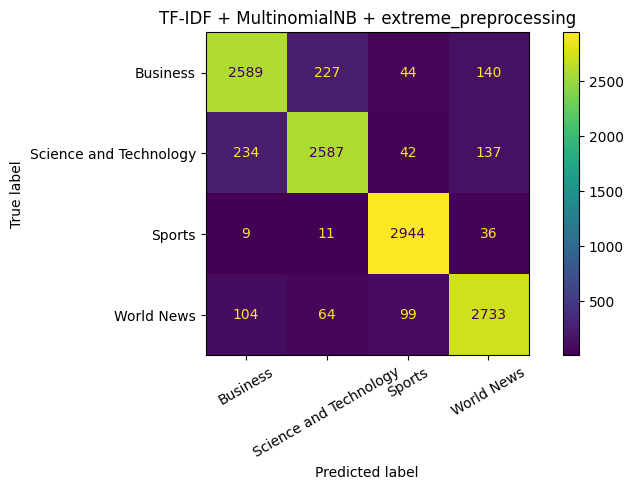


TF-IDF + MultinomialNB: optimum_preprocessing


,alpha,max_features,ngram_range,val_accuracy,val_macro_f1
2,0.2,30000,"(1, 1)",0.911000,0.897490
3,0.2,30000,"(1, 2)",0.910083,0.896424
0,0.2,15000,"(1, 1)",0.909500,0.895828
7,0.5,30000,"(1, 2)",0.909083,0.895162
4,0.5,15000,"(1, 1)",0.908667,0.895016
6,0.5,30000,"(1, 1)",0.908833,0.894756
11,1.0,30000,"(1, 2)",0.906583,0.892238
1,0.2,15000,"(1, 2)",0.905750,0.891546
5,0.5,15000,"(1, 2)",0.905417,0.891201
8,1.0,15000,"(1, 1)",0.905833,0.891200


Best validation configuration: {'alpha': 0.2, 'max_features': 30000, 'ngram_range': (1, 1)}
Final Test: TF-IDF + MultinomialNB + optimum_preprocessing
Accuracy: 0.9007
Macro F1: 0.9001
                        precision    recall  f1-score   support

              Business       0.88      0.86      0.87      3000
Science and Technology       0.90      0.85      0.87      3000
                Sports       0.94      0.98      0.96      3000
            World News       0.89      0.91      0.90      3000

              accuracy                           0.90     12000
             macro avg       0.90      0.90      0.90     12000
          weighted avg       0.90      0.90      0.90     12000



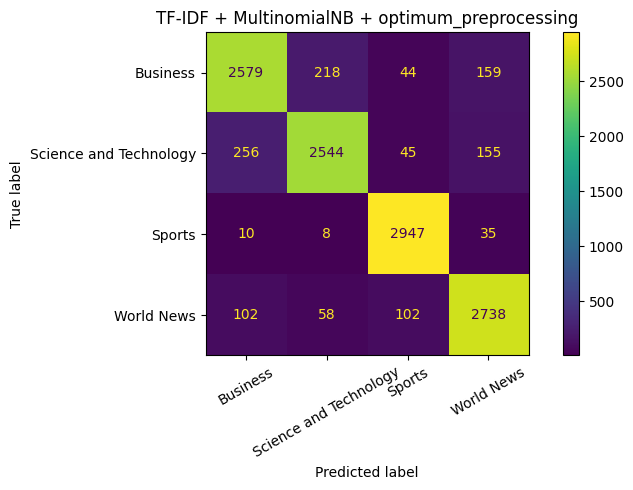

In [15]:
ml_param_grid = list(ParameterGrid({
    "max_features": [15000, 30000],
    "ngram_range": [(1, 1), (1, 2)],
    "alpha": [0.2, 0.5, 1.0],
}))

for prep_name, data in processed_data.items():
    print("\n==============================")
    print("TF-IDF + MultinomialNB:", prep_name)
    print("==============================")
    best = None
    tuning_rows = []

    for params in ml_param_grid:
        vectorizer = TfidfVectorizer(
            max_features=params["max_features"],
            ngram_range=params["ngram_range"],
            min_df=2,
            sublinear_tf=True
        )
        X_train = vectorizer.fit_transform(data["train_texts"])
        X_val = vectorizer.transform(data["val_texts"])

        model = MultinomialNB(alpha=params["alpha"])
        model.fit(X_train, train_labels)
        val_pred = model.predict(X_val)
        val_acc = accuracy_score(val_labels, val_pred)
        val_f1 = f1_score(val_labels, val_pred, average="macro")
        tuning_rows.append({**params, "val_accuracy": val_acc, "val_macro_f1": val_f1})

        if best is None or val_f1 > best["val_macro_f1"]:
            best = {
                "params": params,
                "vectorizer": vectorizer,
                "model": model,
                "val_accuracy": val_acc,
                "val_macro_f1": val_f1,
            }

    tuning_df = pd.DataFrame(tuning_rows).sort_values("val_macro_f1", ascending=False)
    display(tuning_df)
    print("Best validation configuration:", best["params"])

    X_test = best["vectorizer"].transform(data["test_texts"])
    test_pred = best["model"].predict(X_test)
    test_acc, test_f1, test_report, test_matrix = evaluate_predictions(test_labels, test_pred, f"Final Test: TF-IDF + MultinomialNB + {prep_name}")
    plot_confusion(test_matrix, f"TF-IDF + MultinomialNB + {prep_name}")

    log_result(
        prep_name,
        "TF-IDF",
        "MultinomialNB",
        best["params"],
        best["val_accuracy"],
        best["val_macro_f1"],
        test_acc,
        test_f1,
        test_report,
        test_matrix,
        test_pred,
    )

# Part B: TF-IDF with Deep Neural Network

The DNN has 4 dense layers, with at least 128 neurons in the first hidden layer.

## 17. TF-IDF + Deep Neural Network



TF-IDF + Deep Neural Network for preprocessing: no_preprocessing

Training config: {'max_features': 12000, 'ngram_range': (1, 1), 'hidden_dims': (256, 128, 64, 32), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 256, 'epochs': 5}
ERROR! Session/line number was not unique in database. History logging moved to new session 29
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.6004 - loss: 0.9005 - val_accuracy: 0.9153 - val_loss: 0.2668
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9351 - loss: 0.2319 - val_accuracy: 0.9160 - val_loss: 0.2678
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9575 - loss: 0.1447 - val_accuracy: 0.9117 - val_loss: 0.2941
Config result | val_accuracy=0.9153 | val_f1=0.9022

Training config: {'max_features': 15000, 'ngram_range': (1, 2), 'hidden_dims': (512, 256, 128, 64), 'dropout': 0.4, 'lr': 0.0008, 'batch_size': 256, 'epochs': 5}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.6262 - loss

,max_features,ngram_range,hidden_dims,dropout,lr,batch_size,epochs,val_accuracy,val_macro_f1
1,15000,"(1, 2)","(512, 256, 128, 64)",0.4,0.0008,256,5,0.916000,0.903650
0,12000,"(1, 1)","(256, 128, 64, 32)",0.3,0.0010,256,5,0.915333,0.902236


Best validation configuration: {'max_features': 15000, 'ngram_range': (1, 2), 'hidden_dims': (512, 256, 128, 64), 'dropout': 0.4, 'lr': 0.0008, 'batch_size': 256, 'epochs': 5}
Final Test: TF-IDF + DNN + no_preprocessing
Accuracy: 0.905
Macro F1: 0.905
                        precision    recall  f1-score   support

              Business       0.90      0.84      0.87      3000
Science and Technology       0.83      0.92      0.87      3000
                Sports       0.95      0.98      0.97      3000
            World News       0.94      0.88      0.91      3000

              accuracy                           0.91     12000
             macro avg       0.91      0.91      0.91     12000
          weighted avg       0.91      0.91      0.91     12000



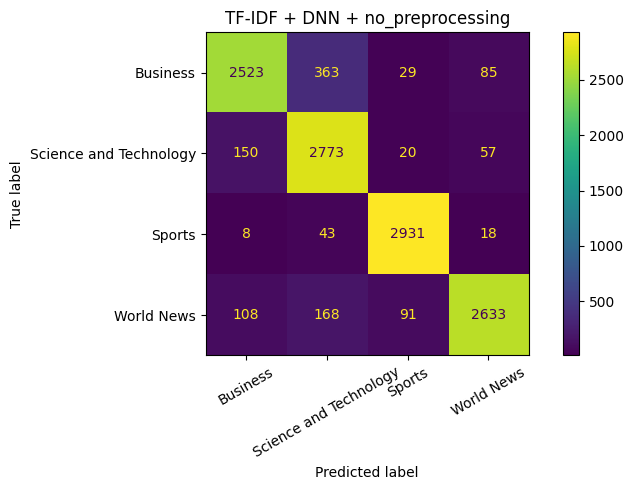


TF-IDF + Deep Neural Network for preprocessing: extreme_preprocessing

Training config: {'max_features': 12000, 'ngram_range': (1, 1), 'hidden_dims': (256, 128, 64, 32), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 256, 'epochs': 5}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 33ms/step - accuracy: 0.6077 - loss: 0.9046 - val_accuracy: 0.9141 - val_loss: 0.2766
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9295 - loss: 0.2467 - val_accuracy: 0.9158 - val_loss: 0.2728
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9559 - loss: 0.1605 - val_accuracy: 0.9120 - val_loss: 0.3003
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9672 - loss: 0.1134 - val_accuracy: 0.9058 - val_loss: 0.3562
Config result | val_accuracy=0.9158 | val_f1=0.9025

Training config: {'max_features': 15000, 'ngram_range': (1, 2), 'hidden_dims': (512, 256, 128, 64), 'dropout': 0.4, 'lr': 0.0008, 'batch_size': 256, 'epochs': 5}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 1

,max_features,ngram_range,hidden_dims,dropout,lr,batch_size,epochs,val_accuracy,val_macro_f1
1,15000,"(1, 2)","(512, 256, 128, 64)",0.4,0.0008,256,5,0.919000,0.906220
0,12000,"(1, 1)","(256, 128, 64, 32)",0.3,0.0010,256,5,0.915833,0.902482


Best validation configuration: {'max_features': 15000, 'ngram_range': (1, 2), 'hidden_dims': (512, 256, 128, 64), 'dropout': 0.4, 'lr': 0.0008, 'batch_size': 256, 'epochs': 5}
Final Test: TF-IDF + DNN + extreme_preprocessing
Accuracy: 0.9118
Macro F1: 0.9116
                        precision    recall  f1-score   support

              Business       0.87      0.88      0.88      3000
Science and Technology       0.90      0.87      0.88      3000
                Sports       0.95      0.98      0.97      3000
            World News       0.92      0.91      0.92      3000

              accuracy                           0.91     12000
             macro avg       0.91      0.91      0.91     12000
          weighted avg       0.91      0.91      0.91     12000



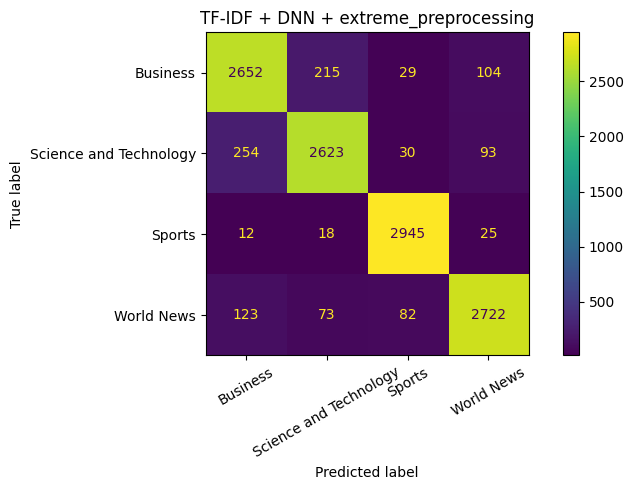


TF-IDF + Deep Neural Network for preprocessing: optimum_preprocessing

Training config: {'max_features': 12000, 'ngram_range': (1, 1), 'hidden_dims': (256, 128, 64, 32), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 256, 'epochs': 5}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 34ms/step - accuracy: 0.5998 - loss: 0.8966 - val_accuracy: 0.9162 - val_loss: 0.2646
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9340 - loss: 0.2289 - val_accuracy: 0.9163 - val_loss: 0.2690
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9608 - loss: 0.1377 - val_accuracy: 0.9106 - val_loss: 0.3057
Config result | val_accuracy=0.9162 | val_f1=0.9034

Training config: {'max_features': 15000, 'ngram_range': (1, 2), 'hidden_dims': (512, 256, 128, 64), 'dropout': 0.4, 'lr': 0.0008, 'batch_size': 256, 'epochs': 5}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.6349 - loss: 0.8399 - val_accuracy: 0.9111 - val_loss: 0.2655
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 

,max_features,ngram_range,hidden_dims,dropout,lr,batch_size,epochs,val_accuracy,val_macro_f1
0,12000,"(1, 1)","(256, 128, 64, 32)",0.3,0.0010,256,5,0.916167,0.903448
1,15000,"(1, 2)","(512, 256, 128, 64)",0.4,0.0008,256,5,0.911083,0.898047


Best validation configuration: {'max_features': 12000, 'ngram_range': (1, 1), 'hidden_dims': (256, 128, 64, 32), 'dropout': 0.3, 'lr': 0.001, 'batch_size': 256, 'epochs': 5}
Final Test: TF-IDF + DNN + optimum_preprocessing
Accuracy: 0.9101
Macro F1: 0.9097
                        precision    recall  f1-score   support

              Business       0.89      0.86      0.88      3000
Science and Technology       0.88      0.88      0.88      3000
                Sports       0.95      0.98      0.97      3000
            World News       0.91      0.91      0.91      3000

              accuracy                           0.91     12000
             macro avg       0.91      0.91      0.91     12000
          weighted avg       0.91      0.91      0.91     12000



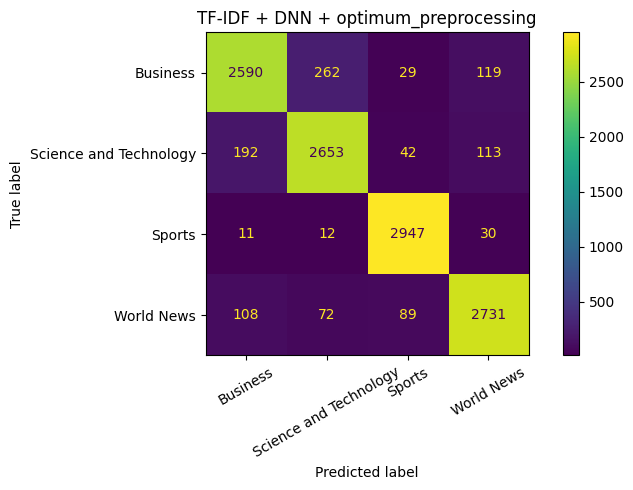

In [20]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

def build_dnn_model(input_dim, hidden_dims, dropout_rate, learning_rate):
    """Dynamically builds a Keras DNN based on a list of hidden layer dimensions."""
    model = Sequential()

    # First hidden layer requires the input shape
    model.add(Dense(hidden_dims[0], activation="relu", input_shape=(input_dim,)))
    model.add(Dropout(dropout_rate))

    # Subsequent hidden layers
    for units in hidden_dims[1:]:
        model.add(Dense(units, activation="relu"))
        model.add(Dropout(dropout_rate))

    model.add(Dense(num_classes, activation="softmax"))

    # Updated compile step
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

def run_tfidf_dnn(prep_name, data):
    print("\n" + "=" * 80)
    print(f"TF-IDF + Deep Neural Network for preprocessing: {prep_name}")
    print("=" * 80)

    # Define the parameter grid from your original setup
    dnn_param_grid = [
    {"max_features": 12000, "ngram_range": (1, 1), "hidden_dims": (256, 128, 64, 32), "dropout": 0.3, "lr": 1e-3, "batch_size": 256, "epochs": 5},
    {"max_features": 15000, "ngram_range": (1, 2), "hidden_dims": (512, 256, 128, 64), "dropout": 0.4, "lr": 8e-4, "batch_size": 256, "epochs": 5},
    ]

    best_config = None
    tuning_rows = []

    for params in dnn_param_grid:
        print(f"\nTraining config: {params}")

        # 1. Vectorization
        vectorizer = TfidfVectorizer(
            max_features=params["max_features"],
            ngram_range=params["ngram_range"],
            min_df=2,
            sublinear_tf=True
        )

        # Keras expects dense numpy arrays, so we use .toarray() on the sparse matrix
        X_train_tfidf = vectorizer.fit_transform(data["train_texts"]).astype("float32").toarray()
        X_val_tfidf = vectorizer.transform(data["val_texts"]).astype("float32").toarray()
        X_test_tfidf = vectorizer.transform(data["test_texts"]).astype("float32").toarray()

        # 2. Build the model
        model = build_dnn_model(
            input_dim=X_train_tfidf.shape[1],
            hidden_dims=params["hidden_dims"],
            dropout_rate=params["dropout"],
            learning_rate=params["lr"]  # Passed but ignored by the new compile step
        )

        # 3. Train the model
        history = model.fit(
            X_train_tfidf,
            train_labels,
            validation_data=(X_val_tfidf, val_labels),
            epochs=params["epochs"],
            batch_size=params["batch_size"],
            verbose=1,
            callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)]
        )

        # 4. Evaluate on validation set
        val_pred = np.argmax(model.predict(X_val_tfidf, verbose=0), axis=1)
        val_accuracy = accuracy_score(val_labels, val_pred)
        val_f1 = f1_score(val_labels, val_pred, average="macro")

        print(f"Config result | val_accuracy={val_accuracy:.4f} | val_f1={val_f1:.4f}")

        tuning_rows.append({**params, "val_accuracy": val_accuracy, "val_macro_f1": val_f1})

        # 5. Track the best configuration
        if best_config is None or val_f1 > best_config["val_macro_f1"]:
            best_config = {
                "params": params,
                "val_accuracy": val_accuracy,
                "val_macro_f1": val_f1,
                "model": model,
                "X_test_tfidf": X_test_tfidf
            }

    # 6. Display tuning summary
    print("\n--- Tuning Summary ---")
    tuning_df = pd.DataFrame(tuning_rows).sort_values("val_macro_f1", ascending=False)
    display(tuning_df)
    print("Best validation configuration:", best_config["params"])

    # 7. Final Evaluation on Test Set using the best model
    best_model = best_config["model"]
    test_pred = np.argmax(best_model.predict(best_config["X_test_tfidf"], verbose=0), axis=1)

    test_acc = accuracy_score(test_labels, test_pred)
    test_f1 = f1_score(test_labels, test_pred, average="macro")

    # Generate reports, plots, and logs using your existing environment functions
    _, _, test_report, test_matrix = evaluate_predictions(test_labels, test_pred, f"Final Test: TF-IDF + DNN + {prep_name}")
    plot_confusion(test_matrix, f"TF-IDF + DNN + {prep_name}")

    log_result(
        prep_name,
        "TF-IDF",
        "Deep Neural Network",
        best_config["params"],
        best_config["val_accuracy"],
        best_config["val_macro_f1"],
        test_acc,
        test_f1,
        test_report,
        test_matrix,
        test_pred,
    )

# Execute the pipeline over the dictionary
for prep_name, data in processed_data.items():
    run_tfidf_dnn(prep_name, data)

# Part C: Skip-gram Word2Vec with Recurrent Neural Networks





## 22. Skip-gram + All Required RNN Experiments

The following six model types are required:

- SimpleRNN
- GRU
- LSTM
- Bidirectional SimpleRNN
- Bidirectional GRU
- Bidirectional LSTM

In [33]:
import re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Embedding, SimpleRNN, GRU, LSTM, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from gensim.models import Word2Vec

# --- Global Constants ---
WORD2VEC_VECTOR_SIZE = 100
MAX_SEQUENCE_LEN = 45
EPOCHS_RNN = 5
BATCH_SIZE = 256

def tokenize_for_sequence(text):
    text = str(text).lower()
    return re.findall(r"[a-z0-9']+", text)

def prepare_skipgram_sequences(train_texts, val_texts, test_texts, vector_size=100, max_len=45):
    """Trains Word2Vec and pads sequences for Keras."""
    train_tokens = [tokenize_for_sequence(t) for t in train_texts]
    val_tokens = [tokenize_for_sequence(t) for t in val_texts]
    test_tokens = [tokenize_for_sequence(t) for t in test_texts]

    w2v_model = Word2Vec(sentences=train_tokens, vector_size=vector_size, window=5, min_count=2, sg=1, workers=4, epochs=8)

    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word in w2v_model.wv.index_to_key:
        vocab[word] = len(vocab)

    vocab_size = len(vocab)
    embedding_matrix = np.zeros((vocab_size, vector_size), dtype=np.float32)
    embedding_matrix[1] = np.random.normal(0, 0.05, vector_size)

    for word, idx in vocab.items():
        if word in w2v_model.wv:
            embedding_matrix[idx] = w2v_model.wv[word]

    def text_to_ids(tokens):
        ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens[:max_len]]
        return ids if len(ids) > 0 else [vocab["<UNK>"]]

    train_seq = [text_to_ids(t) for t in train_tokens]
    val_seq = [text_to_ids(t) for t in val_tokens]
    test_seq = [text_to_ids(t) for t in test_tokens]

    X_train_pad = pad_sequences(train_seq, maxlen=max_len, padding='post', truncating='post')
    X_val_pad = pad_sequences(val_seq, maxlen=max_len, padding='post', truncating='post')
    X_test_pad = pad_sequences(test_seq, maxlen=max_len, padding='post', truncating='post')

    return X_train_pad, X_val_pad, X_test_pad, embedding_matrix, vocab_size

def build_sequence_model(model_type, embedding_matrix, vocab_size, hidden_units, dropout_rate, learning_rate, bidirectional=False):
    model = Sequential()
    model.add(Embedding(
        input_dim=vocab_size,
        output_dim=WORD2VEC_VECTOR_SIZE,
        weights=[embedding_matrix],
        input_length=MAX_SEQUENCE_LEN,
        trainable=True
    ))

    if model_type == "SimpleRNN":
        recurrent_layer = SimpleRNN(hidden_units, dropout=dropout_rate)
    elif model_type == "GRU":
        recurrent_layer = GRU(hidden_units, dropout=dropout_rate)
    elif model_type == "LSTM":
        recurrent_layer = LSTM(hidden_units, dropout=dropout_rate)

    if bidirectional:
        model.add(Bidirectional(recurrent_layer))
    else:
        model.add(recurrent_layer)
    model.add(Dense(128, activation="relu"))
    model.add(Dropout(dropout_rate))
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(dropout_rate))
    model.add(Dense(32, activation="relu"))
    model.add(Dropout(dropout_rate))
    model.add(Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def save_confusion_matrix(y_true, y_pred, title, filename=None):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap='Blues')
    plt.title(title)
    plt.xticks(range(num_classes), class_names, rotation=35, ha="right")
    plt.yticks(range(num_classes), class_names)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            # Fixed the syntax error on this line:
            plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

def evaluate_and_log(preprocessing, representation, model_name, hyperparameters, y_true, y_pred, val_accuracy, val_f1):
    test_accuracy = accuracy_score(y_true, y_pred)
    test_f1 = f1_score(y_true, y_pred, average="macro")
    experiment_name = f"{preprocessing} | {representation} | {model_name}"

    print("\nExperiment:", experiment_name)
    print("Best hyperparameters:", hyperparameters)
    print("Validation accuracy:", round(val_accuracy, 4))
    print("Validation macro F1:", round(val_f1, 4))
    print("Test accuracy:", round(test_accuracy, 4))
    print("Test macro F1:", round(test_f1, 4))
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=class_names))

    # Generate and plot confusion matrix
    save_confusion_matrix(y_true, y_pred, title=experiment_name)

from sklearn.metrics import classification_report, confusion_matrix

def run_custom_skipgram_experiment(mode, display_name, model_type, bidirectional, custom_configs, data):
    """Core logic to run grid search using custom configurations and log results."""
    print("\n" + "=" * 80)
    print(f"Skip-gram + {display_name} for preprocessing: {mode}")
    print("=" * 80)
    
    X_train_pad, X_val_pad, X_test_pad, embedding_matrix, vocab_size = prepare_skipgram_sequences(
        data["train_texts"], data["val_texts"], data["test_texts"], 
        vector_size=WORD2VEC_VECTOR_SIZE, max_len=MAX_SEQUENCE_LEN
    )
    
    best_config = None
    for config in custom_configs:
        print(f"\nTraining config: {config}")
        model = build_sequence_model(
            model_type=model_type,
            embedding_matrix=embedding_matrix,
            vocab_size=vocab_size,
            hidden_units=config["hidden_units"],
            dropout_rate=config["dropout_rate"],
            learning_rate=config["learning_rate"],
            bidirectional=bidirectional
        )
        
        history = model.fit(
            X_train_pad, train_labels,
            validation_data=(X_val_pad, val_labels),
            epochs=EPOCHS_RNN,
            batch_size=BATCH_SIZE,
            verbose=1,
            callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)]
        )
        
        val_pred = np.argmax(model.predict(X_val_pad, verbose=0), axis=1)
        val_accuracy = accuracy_score(val_labels, val_pred)
        val_f1 = f1_score(val_labels, val_pred, average="macro")
        print(f"Config result | val_accuracy={val_accuracy:.4f} | val_f1={val_f1:.4f}")
        
        if best_config is None or val_f1 > best_config["val_f1"]:
            best_config = {"config": config, "val_accuracy": val_accuracy, "val_f1": val_f1, "model": model}
            
    print(f"\nBest Validation F1 for {display_name}: {best_config['val_f1']:.4f}")
    
    # --- Final Evaluation on Test Set ---
    best_model = best_config["model"]
    test_pred = np.argmax(best_model.predict(X_test_pad, verbose=0), axis=1)
    
    test_acc = accuracy_score(test_labels, test_pred)
    test_f1 = f1_score(test_labels, test_pred, average="macro")
    
    # Generate report and matrix for logging
    test_report = classification_report(test_labels, test_pred, target_names=class_names, output_dict=True)
    test_matrix = confusion_matrix(test_labels, test_pred)
    
    # Plot the confusion matrix visually
    save_confusion_matrix(test_labels, test_pred, title=f"Skip-gram + {display_name} + {mode}")
    
    # --- Log the Result ---
    # Using your global log_result function
    log_result(
        mode,                       # prep_name
        "Skip-gram",                # representation
        display_name,               # model_name (e.g., SimpleRNN, LSTM)
        best_config["config"],      # best hyperparameter dict
        best_config["val_accuracy"],
        best_config["val_f1"],
        test_acc,
        test_f1,
        test_report,
        test_matrix,
        test_pred
    )


Skip-gram + SimpleRNN for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.5526 - loss: 1.0216 - val_accuracy: 0.8183 - val_loss: 0.4803
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8158 - loss: 0.5546 - val_accuracy: 0.8512 - val_loss: 0.4492
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8559 - loss: 0.4693 - val_accuracy: 0.8748 - val_loss: 0.3774
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8719 - loss: 0.4278 - val_accuracy: 0.8874 - val_loss: 0.3430
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8919 - loss: 0.3721 - val_accuracy: 0.9009 - val_loss: 0.3195
Config result | val_accuracy=0.9009 | val_f1=0.8842

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.005}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.3029 - loss

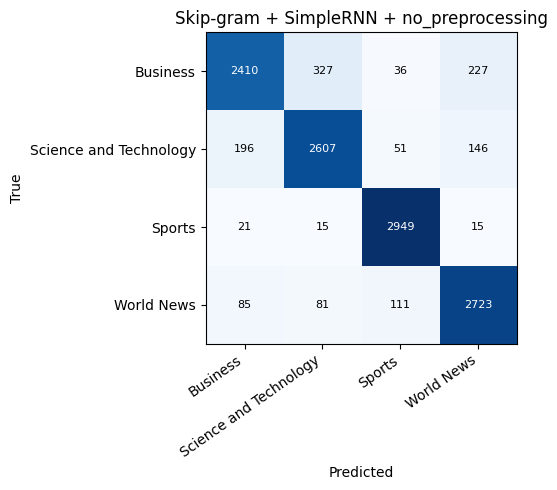


Skip-gram + SimpleRNN for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.4577 - loss: 1.2065 - val_accuracy: 0.3305 - val_loss: 1.3463
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3399 - loss: 1.3373 - val_accuracy: 0.3121 - val_loss: 1.3379
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3471 - loss: 1.3284 - val_accuracy: 0.3383 - val_loss: 1.3363
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3503 - loss: 1.3223 - val_accuracy: 0.3380 - val_loss: 1.3369
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3536 - loss: 1.3218 - val_accuracy: 0.3415 - val_loss: 1.3321
Config result | val_accuracy=0.3415 | val_f1=0.1514

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.005}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.3065 -

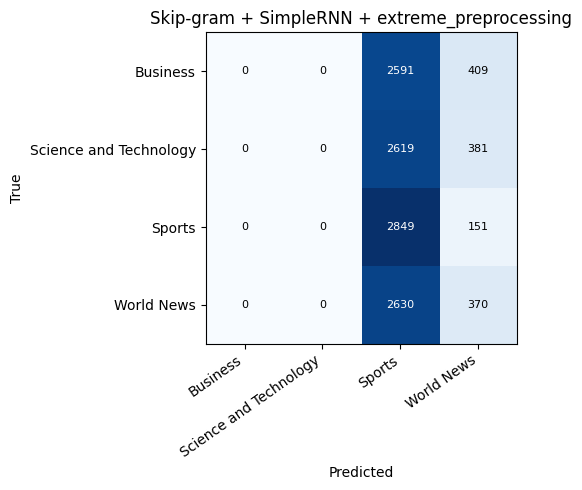


Skip-gram + SimpleRNN for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.4465 - loss: 1.2162 - val_accuracy: 0.3305 - val_loss: 1.3494
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3251 - loss: 1.3519 - val_accuracy: 0.3305 - val_loss: 1.3466
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3272 - loss: 1.3438 - val_accuracy: 0.3305 - val_loss: 1.3423
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3316 - loss: 1.3392 - val_accuracy: 0.3305 - val_loss: 1.3455
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3255 - loss: 1.3445 - val_accuracy: 0.3305 - val_loss: 1.3442
Config result | val_accuracy=0.3305 | val_f1=0.1242

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.005}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.3072 -

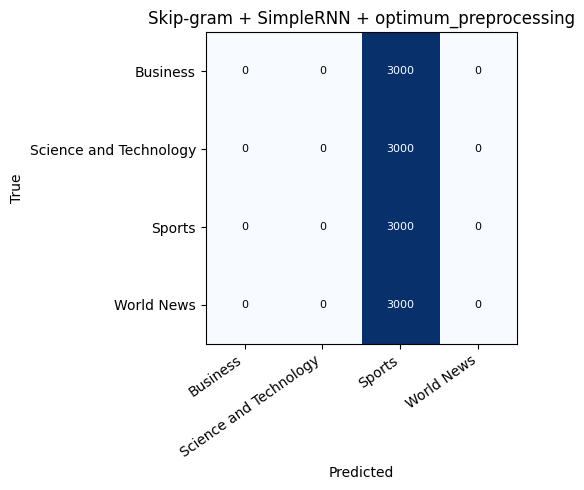

In [34]:
#1.Simple RNN

simple_rnn_configs = [
    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.005},
    ]

for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="SimpleRNN",
        model_type="SimpleRNN",
        bidirectional=False,
        custom_configs=simple_rnn_configs,
        data=data
    )


Skip-gram + GRU for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.5924 - loss: 0.9179 - val_accuracy: 0.8943 - val_loss: 0.3349
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8815 - loss: 0.3879 - val_accuracy: 0.9091 - val_loss: 0.2754
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9089 - loss: 0.3041 - val_accuracy: 0.9193 - val_loss: 0.2442
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9206 - loss: 0.2625 - val_accuracy: 0.9233 - val_loss: 0.2336
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9304 - loss: 0.2306 - val_accuracy: 0.9250 - val_loss: 0.2394
Config result | val_accuracy=0.9233 | val_f1=0.9107

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.003}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.5153 - loss: 1.088

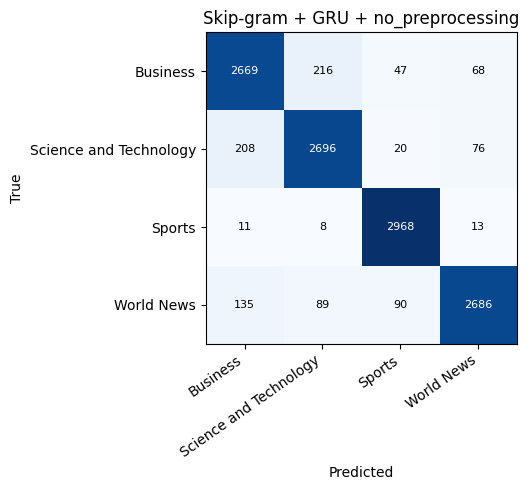


Skip-gram + GRU for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4108 - loss: 1.2044 - val_accuracy: 0.7822 - val_loss: 0.4654
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7672 - loss: 0.5188 - val_accuracy: 0.8463 - val_loss: 0.4241
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8374 - loss: 0.4252 - val_accuracy: 0.9096 - val_loss: 0.2801
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9057 - loss: 0.3121 - val_accuracy: 0.9182 - val_loss: 0.2571
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9142 - loss: 0.2760 - val_accuracy: 0.9203 - val_loss: 0.2560
Config result | val_accuracy=0.9203 | val_f1=0.9066

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.003}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.3188 - loss: 

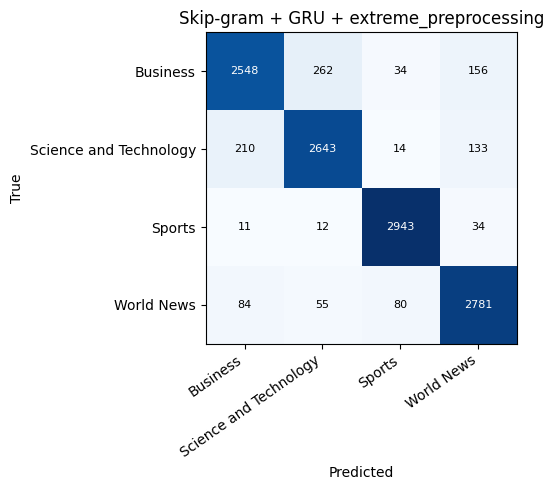


Skip-gram + GRU for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5497 - loss: 0.9809 - val_accuracy: 0.8748 - val_loss: 0.3988
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8643 - loss: 0.4217 - val_accuracy: 0.9075 - val_loss: 0.2912
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9053 - loss: 0.3222 - val_accuracy: 0.9194 - val_loss: 0.2608
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9142 - loss: 0.2853 - val_accuracy: 0.9226 - val_loss: 0.2349
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9286 - loss: 0.2395 - val_accuracy: 0.9226 - val_loss: 0.2469
Config result | val_accuracy=0.9226 | val_f1=0.9098

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.003}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.4551 - loss: 

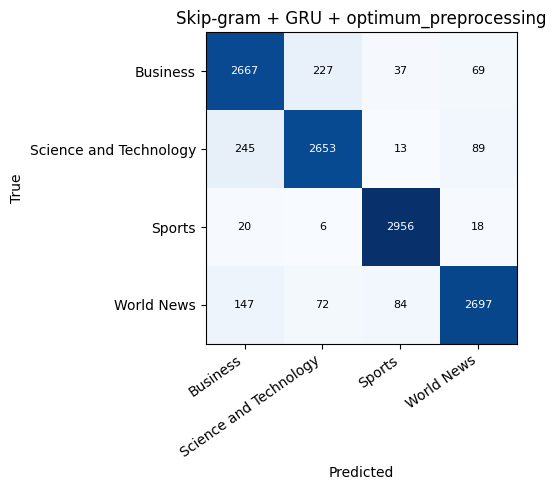

In [45]:
#2.GRU

gru_configs = [
    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.003},
    ]

for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="GRU",
        model_type="GRU",
        bidirectional=False,
        custom_configs=gru_configs ,
        data=data
    )


Skip-gram + LSTM for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.6530 - loss: 0.8242 - val_accuracy: 0.9031 - val_loss: 0.3090
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8839 - loss: 0.3850 - val_accuracy: 0.9110 - val_loss: 0.2795
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9026 - loss: 0.3185 - val_accuracy: 0.9178 - val_loss: 0.2534
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9170 - loss: 0.2755 - val_accuracy: 0.9207 - val_loss: 0.2441
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9265 - loss: 0.2418 - val_accuracy: 0.9243 - val_loss: 0.2461
Config result | val_accuracy=0.9207 | val_f1=0.9078

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.004}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 46ms/step - accuracy: 0.5375 - loss: 1.09

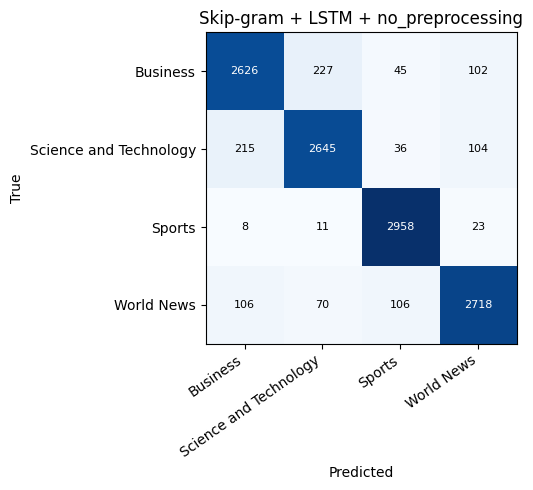


Skip-gram + LSTM for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6178 - loss: 0.8491 - val_accuracy: 0.8907 - val_loss: 0.3614
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8559 - loss: 0.4412 - val_accuracy: 0.8977 - val_loss: 0.3225
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.8941 - loss: 0.3612 - val_accuracy: 0.8939 - val_loss: 0.3285
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9067 - loss: 0.3222 - val_accuracy: 0.9167 - val_loss: 0.2748
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9150 - loss: 0.2913 - val_accuracy: 0.9177 - val_loss: 0.2749
Config result | val_accuracy=0.9167 | val_f1=0.9033

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.004}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.3667 - loss:

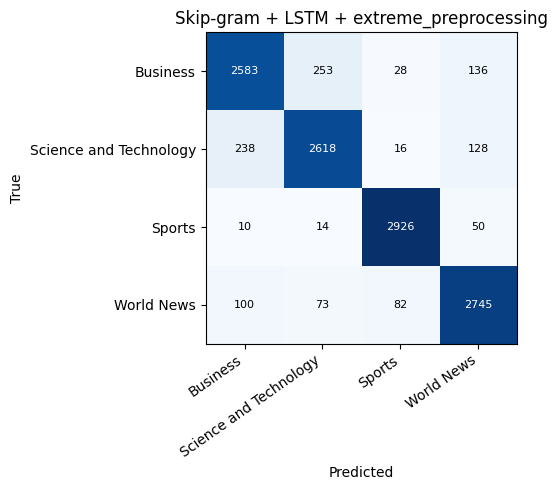


Skip-gram + LSTM for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.6023 - loss: 0.8950 - val_accuracy: 0.8892 - val_loss: 0.3613
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8719 - loss: 0.4302 - val_accuracy: 0.9117 - val_loss: 0.2903
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9017 - loss: 0.3449 - val_accuracy: 0.9150 - val_loss: 0.2752
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9114 - loss: 0.2987 - val_accuracy: 0.9182 - val_loss: 0.2652
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9202 - loss: 0.2680 - val_accuracy: 0.9199 - val_loss: 0.2542
Config result | val_accuracy=0.9199 | val_f1=0.9068

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.004}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - accuracy: 0.4606 - loss:

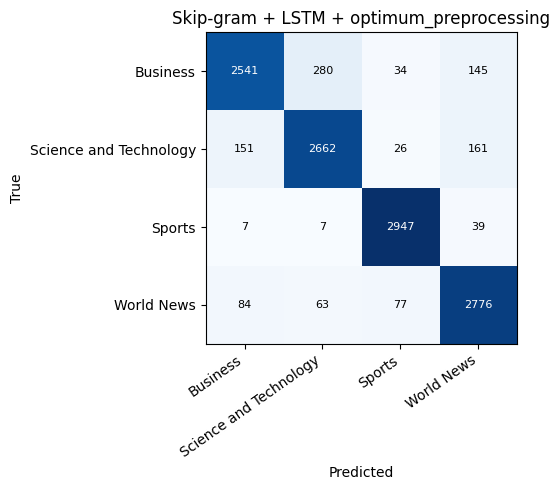

In [47]:
#3.LSTM

lstm_configs = [

    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.004},
    ]

for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="LSTM",
        model_type="LSTM",
        bidirectional=False,
        custom_configs=lstm_configs,
        data=data
    )


Skip-gram + Bidirectional SimpleRNN for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step - accuracy: 0.5943 - loss: 0.9520 - val_accuracy: 0.8682 - val_loss: 0.3922
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8461 - loss: 0.4777 - val_accuracy: 0.8947 - val_loss: 0.3224
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8786 - loss: 0.3971 - val_accuracy: 0.8973 - val_loss: 0.3153
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8867 - loss: 0.3763 - val_accuracy: 0.9083 - val_loss: 0.3022
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9078 - loss: 0.3149 - val_accuracy: 0.9027 - val_loss: 0.3048
Config result | val_accuracy=0.9083 | val_f1=0.8933

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.007}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy:

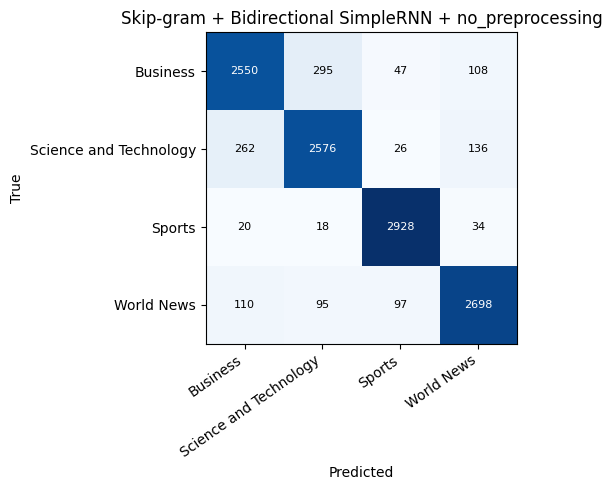


Skip-gram + Bidirectional SimpleRNN for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.6712 - loss: 0.8118 - val_accuracy: 0.8943 - val_loss: 0.3289
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8697 - loss: 0.4358 - val_accuracy: 0.8944 - val_loss: 0.3224
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8890 - loss: 0.3692 - val_accuracy: 0.9089 - val_loss: 0.2920
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8979 - loss: 0.3313 - val_accuracy: 0.9061 - val_loss: 0.3032
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9044 - loss: 0.3198 - val_accuracy: 0.9112 - val_loss: 0.2844
Config result | val_accuracy=0.9112 | val_f1=0.8960

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.007}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accu

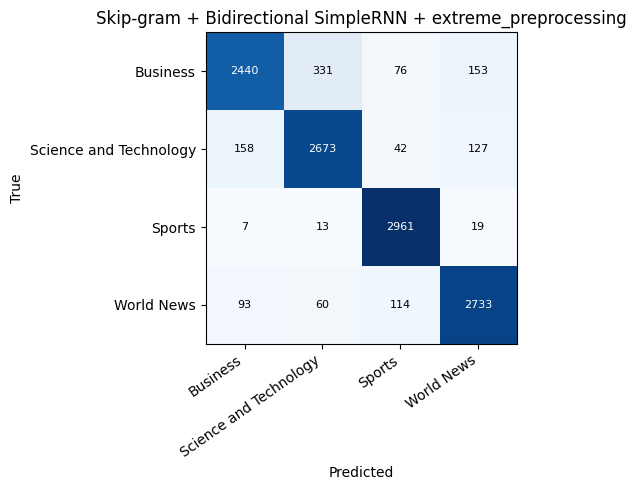


Skip-gram + Bidirectional SimpleRNN for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step - accuracy: 0.6594 - loss: 0.8559 - val_accuracy: 0.8848 - val_loss: 0.3732
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8523 - loss: 0.4867 - val_accuracy: 0.8900 - val_loss: 0.3470
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8740 - loss: 0.4182 - val_accuracy: 0.9028 - val_loss: 0.3099
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8911 - loss: 0.3601 - val_accuracy: 0.9108 - val_loss: 0.2813
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8972 - loss: 0.3406 - val_accuracy: 0.9059 - val_loss: 0.3098
Config result | val_accuracy=0.9108 | val_f1=0.8973

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.007}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accu

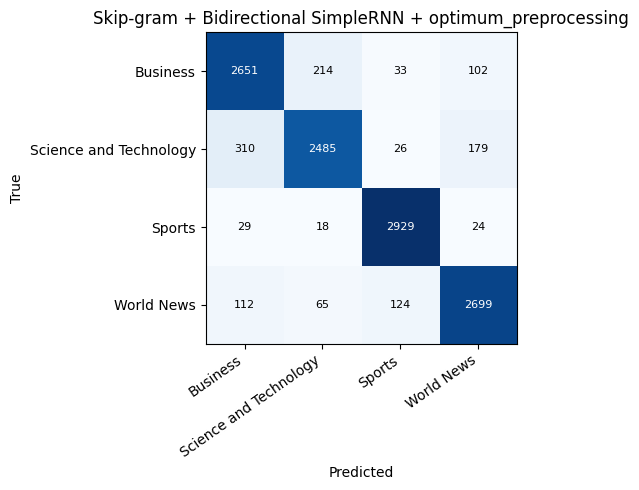

In [48]:
#4.Bidirectional Simple RNN

bi_simple_rnn_configs = [
    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.007},
    ]

for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="Bidirectional SimpleRNN",
        model_type="SimpleRNN",
        bidirectional=True,
        custom_configs=bi_simple_rnn_configs,
        data=data
    )


Skip-gram + Bidirectional GRU for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.5673 - loss: 0.9550 - val_accuracy: 0.9032 - val_loss: 0.3029
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8910 - loss: 0.3655 - val_accuracy: 0.9151 - val_loss: 0.2700
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9154 - loss: 0.2844 - val_accuracy: 0.9222 - val_loss: 0.2390
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9295 - loss: 0.2319 - val_accuracy: 0.9263 - val_loss: 0.2290
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9359 - loss: 0.2086 - val_accuracy: 0.9242 - val_loss: 0.2398
Config result | val_accuracy=0.9263 | val_f1=0.9146

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.008}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.3159

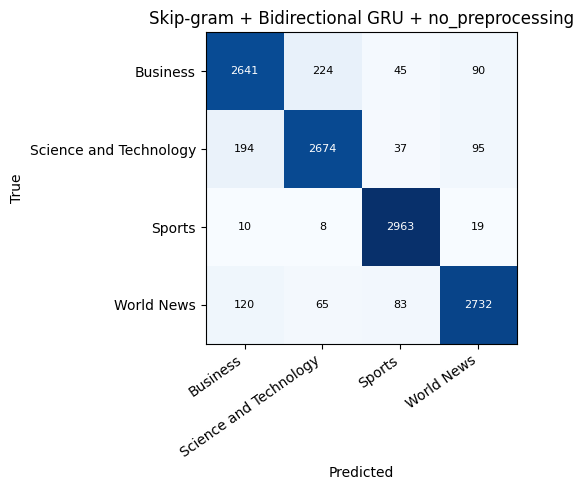


Skip-gram + Bidirectional GRU for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.7247 - loss: 0.7235 - val_accuracy: 0.9067 - val_loss: 0.2857
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.8934 - loss: 0.3569 - val_accuracy: 0.9166 - val_loss: 0.2558
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9102 - loss: 0.2959 - val_accuracy: 0.9150 - val_loss: 0.2534
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9164 - loss: 0.2629 - val_accuracy: 0.9243 - val_loss: 0.2290
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9253 - loss: 0.2376 - val_accuracy: 0.9213 - val_loss: 0.2352
Config result | val_accuracy=0.9243 | val_f1=0.9113

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.008}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0

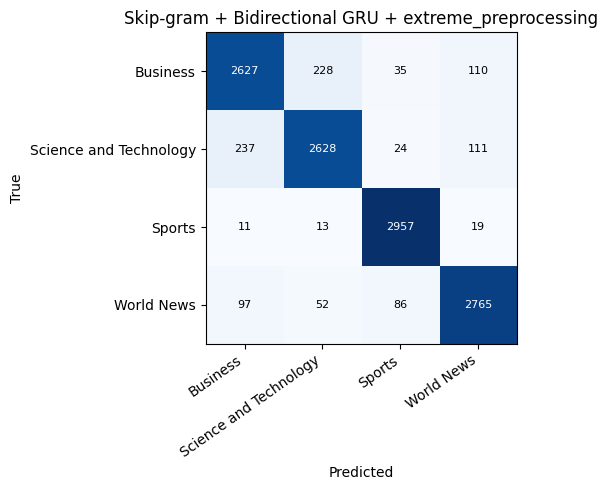


Skip-gram + Bidirectional GRU for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.6895 - loss: 0.7700 - val_accuracy: 0.9062 - val_loss: 0.2890
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8940 - loss: 0.3525 - val_accuracy: 0.9168 - val_loss: 0.2581
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9104 - loss: 0.2896 - val_accuracy: 0.9202 - val_loss: 0.2423
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9267 - loss: 0.2389 - val_accuracy: 0.9271 - val_loss: 0.2295
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9341 - loss: 0.2093 - val_accuracy: 0.9253 - val_loss: 0.2364
Config result | val_accuracy=0.9271 | val_f1=0.9154

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.008}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0

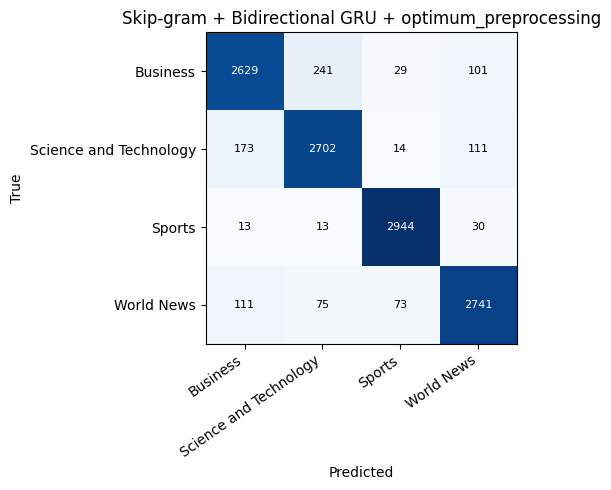

In [49]:
#5.Bidirectional GRU

bi_gru_configs = [
    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.008},
    ]


for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="Bidirectional GRU",
        model_type="GRU",
        bidirectional=True,
        custom_configs=bi_gru_configs,
        data=data
    )


Skip-gram + Bidirectional LSTM for preprocessing: no_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.6894 - loss: 0.7732 - val_accuracy: 0.9033 - val_loss: 0.3029
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8913 - loss: 0.3578 - val_accuracy: 0.9153 - val_loss: 0.2632
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9152 - loss: 0.2871 - val_accuracy: 0.9197 - val_loss: 0.2356
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9240 - loss: 0.2455 - val_accuracy: 0.9194 - val_loss: 0.2454
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9338 - loss: 0.2104 - val_accuracy: 0.9244 - val_loss: 0.2343
Config result | val_accuracy=0.9244 | val_f1=0.9128

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.009}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 77ms/step - accuracy: 0.32

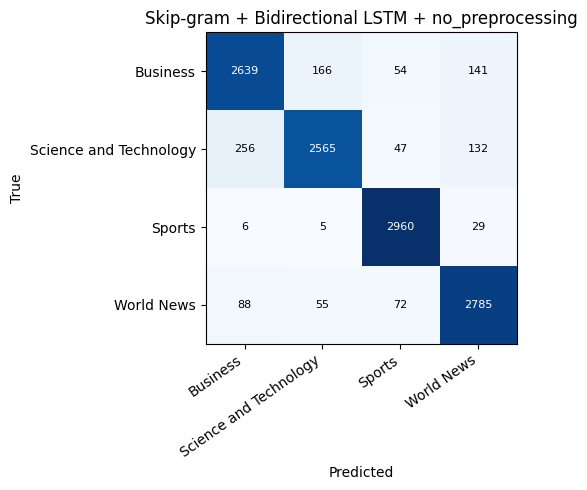


Skip-gram + Bidirectional LSTM for preprocessing: extreme_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.7388 - loss: 0.6797 - val_accuracy: 0.9053 - val_loss: 0.2810
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.8941 - loss: 0.3452 - val_accuracy: 0.9150 - val_loss: 0.2566
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9131 - loss: 0.2809 - val_accuracy: 0.9205 - val_loss: 0.2484
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9167 - loss: 0.2619 - val_accuracy: 0.9211 - val_loss: 0.2455
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9239 - loss: 0.2389 - val_accuracy: 0.9246 - val_loss: 0.2368
Config result | val_accuracy=0.9246 | val_f1=0.9121

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.009}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy:

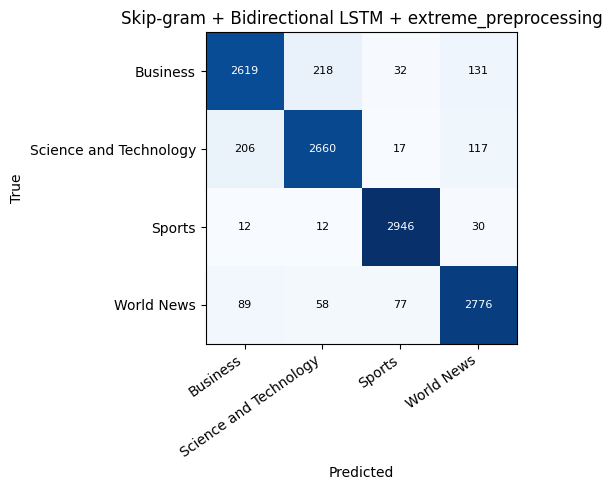


Skip-gram + Bidirectional LSTM for preprocessing: optimum_preprocessing

Training config: {'hidden_units': 256, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.7245 - loss: 0.7189 - val_accuracy: 0.9008 - val_loss: 0.3395
Epoch 2/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8951 - loss: 0.3504 - val_accuracy: 0.9187 - val_loss: 0.2527
Epoch 3/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9128 - loss: 0.2867 - val_accuracy: 0.9177 - val_loss: 0.2460
Epoch 4/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9241 - loss: 0.2444 - val_accuracy: 0.9241 - val_loss: 0.2334
Epoch 5/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9359 - loss: 0.2049 - val_accuracy: 0.9226 - val_loss: 0.2308
Config result | val_accuracy=0.9226 | val_f1=0.9094

Training config: {'hidden_units': 512, 'dropout_rate': 0.5, 'learning_rate': 0.009}
Epoch 1/5
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step - accuracy:

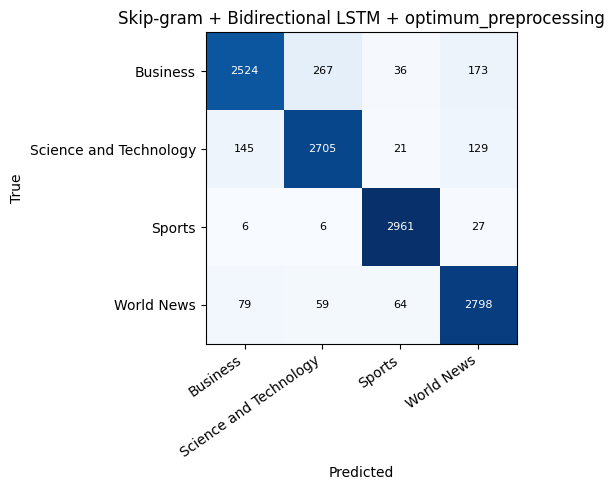

In [50]:
#6.Bidirectional LSTM

bi_lstm_configs = [
    {"hidden_units": 256, "dropout_rate": 0.30, "learning_rate": 0.001},
    {"hidden_units": 512, "dropout_rate": 0.50, "learning_rate": 0.009},
    ]


for mode, data in processed_data.items():
    run_custom_skipgram_experiment(
        mode=mode,
        display_name="Bidirectional LSTM",
        model_type="LSTM",
        bidirectional=True,
        custom_configs=bi_lstm_configs,
        data=data
    )

# Part D: Final Comparison and Report Tables

## 23. Results Table

In [51]:
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values("test_macro_f1", ascending=False).reset_index(drop=True)
display(results_df)



,preprocessing,representation,model,hyperparameters,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,no_preprocessing,Skip-gram,GRU,"{""hidden_units"": 512, ""dropout_rate"": 0.5, ""le...",0.924750,0.912913,0.918250,0.918031
1,optimum_preprocessing,Skip-gram,Bidirectional GRU,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.927083,0.915410,0.918000,0.917798
2,no_preprocessing,Skip-gram,Bidirectional GRU,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.926333,0.914552,0.917500,0.917171
3,extreme_preprocessing,Skip-gram,Bidirectional LSTM,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.924583,0.912056,0.916750,0.916439
4,optimum_preprocessing,Skip-gram,Bidirectional LSTM,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.922583,0.909387,0.915667,0.915118
5,extreme_preprocessing,Skip-gram,Bidirectional GRU,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.924250,0.911307,0.914750,0.914387
6,optimum_preprocessing,Skip-gram,GRU,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.922583,0.909845,0.914417,0.914307
7,no_preprocessing,Skip-gram,LSTM,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.924000,0.911804,0.914250,0.914067
8,no_preprocessing,Skip-gram,Bidirectional LSTM,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.924417,0.912771,0.912417,0.911869
9,no_preprocessing,Skip-gram,LSTM,"{""hidden_units"": 512, ""dropout_rate"": 0.5, ""le...",0.924417,0.912356,0.912250,0.911846


## 24. Best and Worst Model Identification

In [52]:
best_model = results_df.iloc[0]
worst_model = results_df.iloc[-1]

print("Best-performing experiment")
display(best_model.to_frame().T)

print("Worst-performing experiment")
display(worst_model.to_frame().T)

Best-performing experiment


,preprocessing,representation,model,hyperparameters,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
0,no_preprocessing,Skip-gram,GRU,"{""hidden_units"": 512, ""dropout_rate"": 0.5, ""le...",0.92475,0.912913,0.91825,0.918031


Worst-performing experiment


,preprocessing,representation,model,hyperparameters,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1
27,optimum_preprocessing,Skip-gram,SimpleRNN,"{""hidden_units"": 256, ""dropout_rate"": 0.3, ""le...",0.3305,0.124201,0.25,0.1


## 25. Visual Comparison of Model Performance

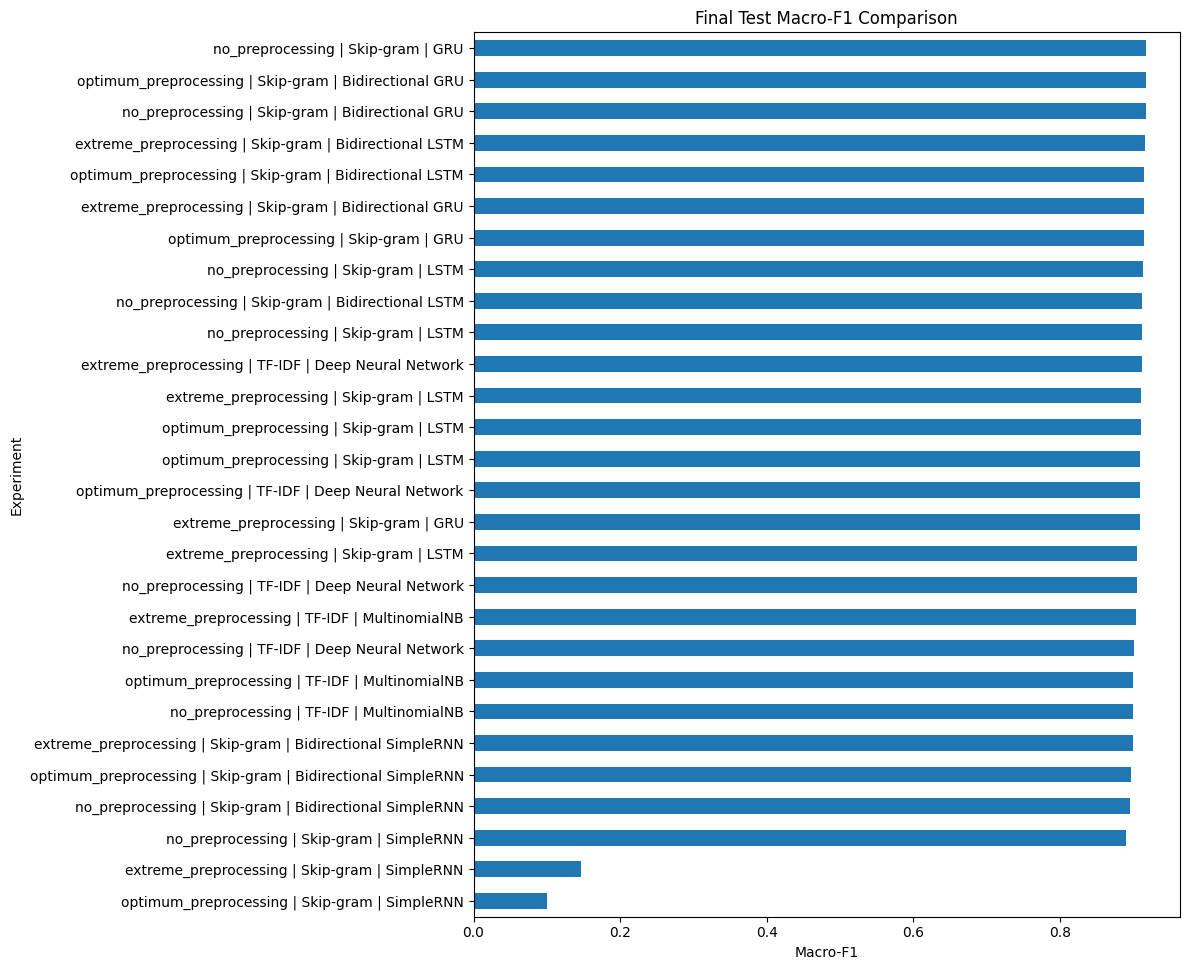

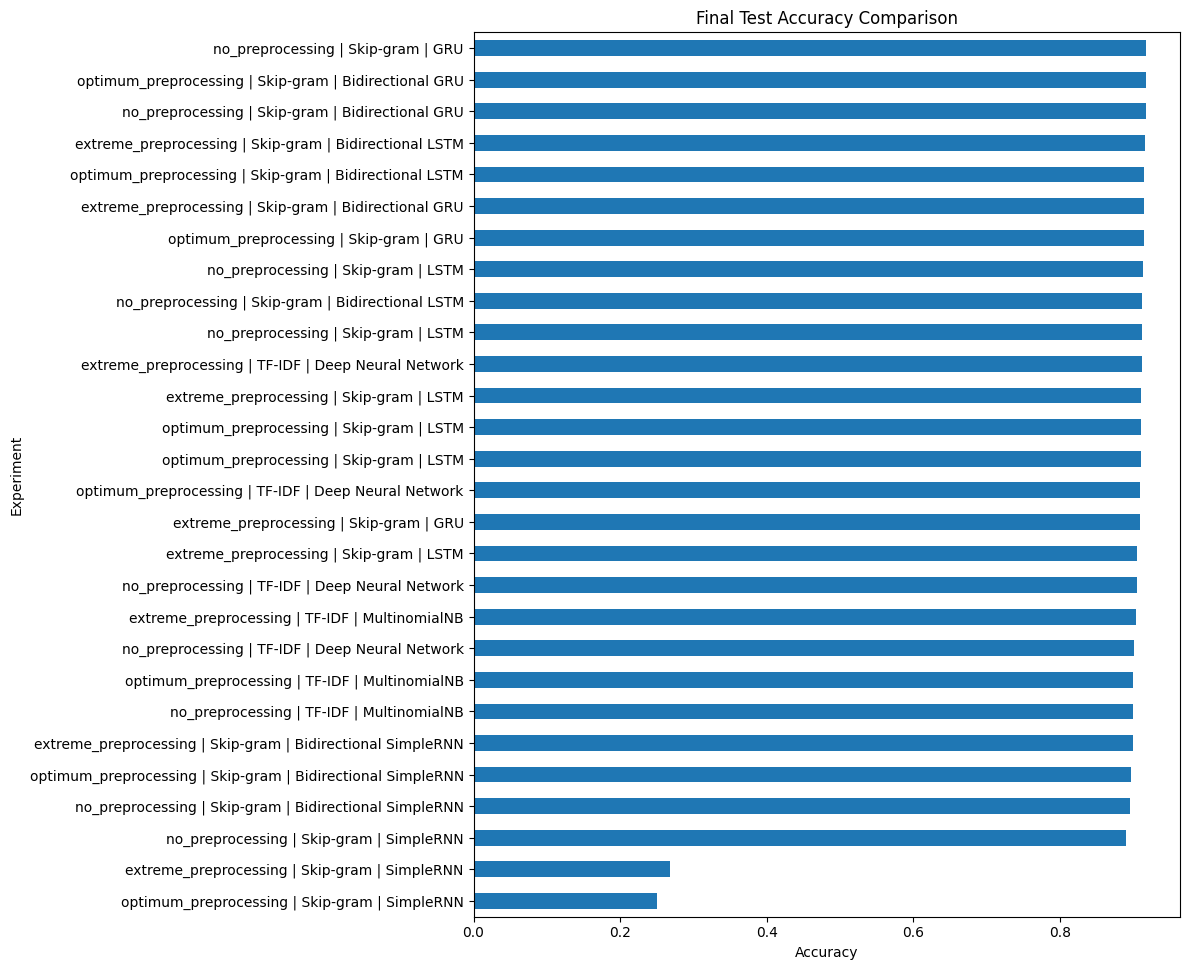

In [53]:
plot_df = results_df.copy()
plot_df["experiment"] = plot_df["preprocessing"] + " | " + plot_df["representation"] + " | " + plot_df["model"]

ax = plot_df.sort_values("test_macro_f1").plot(
    x="experiment",
    y="test_macro_f1",
    kind="barh",
    figsize=(12, max(8, len(plot_df) * 0.35)),
    legend=False
)
ax.set_title("Final Test Macro-F1 Comparison")
ax.set_xlabel("Macro-F1")
ax.set_ylabel("Experiment")
plt.tight_layout()
plt.show()

ax = plot_df.sort_values("test_accuracy").plot(
    x="experiment",
    y="test_accuracy",
    kind="barh",
    figsize=(12, max(8, len(plot_df) * 0.35)),
    legend=False
)
ax.set_title("Final Test Accuracy Comparison")
ax.set_xlabel("Accuracy")
ax.set_ylabel("Experiment")
plt.tight_layout()
plt.show()

## 26. Show Confusion Matrix and Classification Report for Best and Worst Models

Best model key: no_preprocessing | Skip-gram | GRU
                        precision    recall  f1-score      support
Business                 0.882898  0.889667  0.886269   3000.00000
Science and Technology   0.895979  0.898667  0.897321   3000.00000
Sports                   0.949760  0.989333  0.969143   3000.00000
World News               0.944777  0.895333  0.919391   3000.00000
accuracy                 0.918250  0.918250  0.918250      0.91825
macro avg                0.918353  0.918250  0.918031  12000.00000
weighted avg             0.918353  0.918250  0.918031  12000.00000


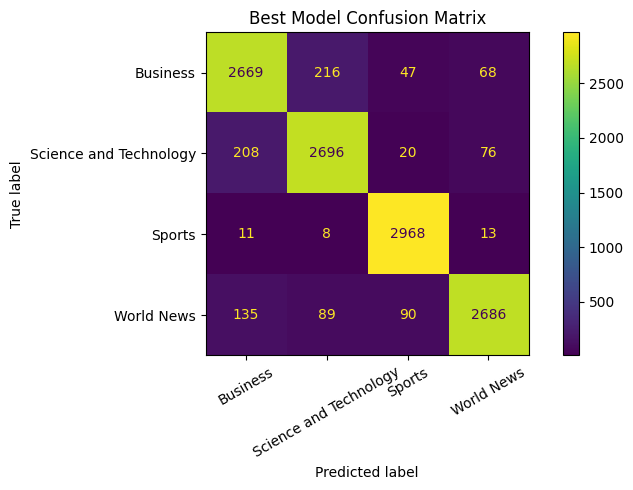

Worst model key: optimum_preprocessing | Skip-gram | SimpleRNN
                        precision  recall  f1-score   support
Business                   0.0000    0.00      0.00   3000.00
Science and Technology     0.0000    0.00      0.00   3000.00
Sports                     0.2500    1.00      0.40   3000.00
World News                 0.0000    0.00      0.00   3000.00
accuracy                   0.2500    0.25      0.25      0.25
macro avg                  0.0625    0.25      0.10  12000.00
weighted avg               0.0625    0.25      0.10  12000.00


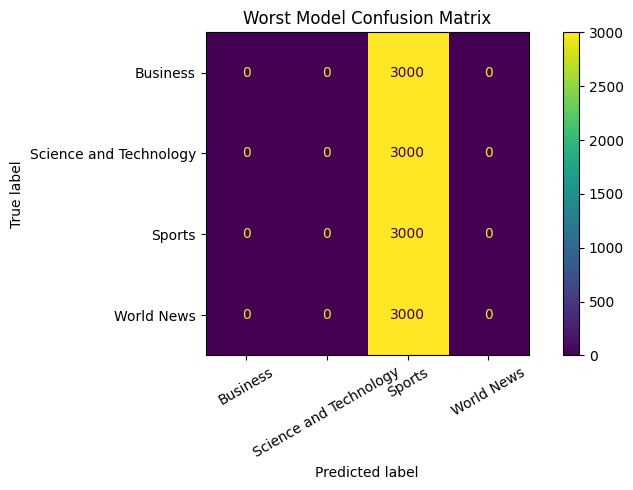

In [54]:
best_key = f"{best_model['preprocessing']} | {best_model['representation']} | {best_model['model']}"
worst_key = f"{worst_model['preprocessing']} | {worst_model['representation']} | {worst_model['model']}"

print("Best model key:", best_key)
print(pd.DataFrame(all_reports[best_key]).T)
plot_confusion(all_confusion_matrices[best_key], "Best Model Confusion Matrix")

print("Worst model key:", worst_key)
print(pd.DataFrame(all_reports[worst_key]).T)
plot_confusion(all_confusion_matrices[worst_key], "Worst Model Confusion Matrix")